# Probability Calibration — Mix Dataset (PoI, 306 features)

**Question**: when a model outputs 0.89 as the probability of its predicted class, is it
actually correct 89% of the time? This is a **calibration** question, distinct from the
conformal-prediction notebook (`conformal_predictions.ipynb`), which asks a different
question — does a *set* of classes cover the truth at a guaranteed rate. Calibration asks
whether the *number itself* is trustworthy.

**Why pool across seeds**: a single seed's test set has only 86 samples — too few to bin
by confidence and get a stable empirical accuracy per bin. Pooling all 10 seeds gives
~860 (prediction, outcome) pairs per model, which is still modest but workable, and lets
us separately check whether calibration itself is stable seed-to-seed (Section 6) rather
than just assuming the pooled number is representative.

**Models**: the paper's four best models (TabPFN Class Weights, Extra Trees, LightGBM,
XGBoost), plus **TabPFN Original** — included specifically to test whether
`balance_probabilities=True` (which rescales posterior probabilities by class frequency
to fix balanced accuracy) comes at a cost to calibration. That rescaling has no reason to
preserve the literal probabilistic meaning of the output, so this is a real empirical
question the paper's own methodology raises.

**What's reported**:
1. Reliability diagrams (predicted confidence vs. empirical accuracy, adaptive bins, Wilson CIs)
2. Expected Calibration Error (ECE) and Maximum Calibration Error (MCE)
3. Multiclass Brier score, decomposed into reliability + resolution + uncertainty
4. Per-bin significance test: is empirical accuracy significantly different from stated confidence?
5. Per-seed ECE stability (is the pooled number representative, or lucky averaging?)
6. TabPFN Original vs. Class Weights — does rebalancing hurt calibration?
7. Per-class calibration — does a 0.89 mean the same thing for every class?

In [1]:
import os, sys, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

_cwd = os.getcwd()
ROOT = _cwd
for _c in [_cwd] + [os.path.abspath(os.path.join(_cwd, *['..'] * i)) for i in range(1, 4)]:
    if os.path.isdir(os.path.join(_c, 'scripts')) and os.path.isdir(os.path.join(_c, 'Mix_Results_PoI')):
        ROOT = _c
        break

sys.path.insert(0, os.path.join(ROOT, 'scripts'))
from model_colors import MODEL_COLORS

RESULTS  = 'Mix_Results_PoI'
FIG_DIR  = os.path.join(ROOT, RESULTS, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

%matplotlib inline
plt.rcParams.update({'figure.dpi': 130, 'font.family': 'sans-serif'})

CLASS_NAMES = ['Allele', 'Back Stutter', 'Forward Stutter', 'Pull-Up']
SEEDS = [42, 123, 456, 789, 1011, 1213, 1415, 1617, 1819, 2021]

print('Project root:', ROOT)

Project root: C:\Users\DT User\Documents\GitHub\ML_in_LTDNA


## 1  Load and pool predictions across all 10 seeds

In [2]:
PROB_COLS_NAMED   = ['Prob_Allele', 'Prob_Back_Stutter', 'Prob_Forward_Stutter', 'Prob_Pull_Up']
PROB_COLS_INDEXED = ['Prob_0', 'Prob_1', 'Prob_2', 'Prob_3']

# (model_key, label, filename, is_tabpfn)
MODELS = [
    ('tabpfn_cw',       'TabPFN (Class Weights)', 'predictions_tabpfn_classweights_v35.csv', True),
    ('tabpfn_original', 'TabPFN (Original)',      'predictions_tabpfn_original_v35.csv',     True),
    ('extratrees',      'Extra Trees (SMOTE)',    'predictions_extratrees_smote.csv',       False),
    ('lgbm',            'LightGBM (SMOTE)',       'predictions_lgbm_smote.csv',             False),
    ('xgboost',         'XGBoost (SMOTE)',        'predictions_xgboost_smote.csv',          False),
]

_display_color = {
    'tabpfn_cw': MODEL_COLORS.get('tabpfn', '#3f51b5'),
    'tabpfn_original': '#9575cd',
    'extratrees': MODEL_COLORS.get('extratrees', '#1565c0'),
    'lgbm': MODEL_COLORS.get('lgbm', '#2e7d32'),
    'xgboost': MODEL_COLORS.get('xgboost', '#e65100'),
}

def seed_dir(seed, is_tabpfn):
    if seed == 42:
        return os.path.join(ROOT, RESULTS, 'data')
    sub = f'seed_{seed}_v35' if is_tabpfn else f'seed_{seed}'
    return os.path.join(ROOT, RESULTS, sub, 'data')

pooled = {}
for key, label, fname, is_tabpfn in MODELS:
    confs, corrects, trues, preds, seed_ids, classes_true = [], [], [], [], [], []
    for seed in SEEDS:
        path = os.path.join(seed_dir(seed, is_tabpfn), fname)
        df = pd.read_csv(path)
        pcols = PROB_COLS_NAMED if PROB_COLS_NAMED[0] in df.columns else PROB_COLS_INDEXED
        probs = df[pcols].values.astype(float)
        y_true = df['True_Label'].values.astype(int)
        y_pred = probs.argmax(axis=1)
        conf = probs.max(axis=1)
        confs.append(conf)
        corrects.append((y_pred == y_true).astype(int))
        trues.append(y_true)
        preds.append(y_pred)
        seed_ids.append(np.full(len(y_true), seed))
        classes_true.append(y_true)
    pooled[key] = {
        'label': label,
        'color': _display_color[key],
        'conf': np.concatenate(confs),
        'correct': np.concatenate(corrects),
        'y_true': np.concatenate(trues),
        'y_pred': np.concatenate(preds),
        'seed': np.concatenate(seed_ids),
    }
    n = len(pooled[key]['conf'])
    acc = pooled[key]['correct'].mean()
    print(f"{label:28s}  n={n}  overall accuracy={acc:.3f}  mean confidence={pooled[key]['conf'].mean():.3f}")

TabPFN (Class Weights)        n=860  overall accuracy=0.864  mean confidence=0.870


TabPFN (Original)             n=860  overall accuracy=0.895  mean confidence=0.880


Extra Trees (SMOTE)           n=860  overall accuracy=0.864  mean confidence=0.716


LightGBM (SMOTE)              n=860  overall accuracy=0.820  mean confidence=0.888


XGBoost (SMOTE)               n=860  overall accuracy=0.822  mean confidence=0.878


## 2  Core calibration functions

`adaptive_bins` uses equal-*count* bins (quantiles of confidence) rather than equal-width
bins. With ~860 pooled points and confidences that cluster near 1.0 (typical for these
classifiers), fixed-width bins leave the low-confidence bins nearly empty; equal-count
bins keep statistical power roughly even across the whole range.

In [3]:
def wilson_ci(k, n, z=1.96):
    """Wilson score interval for a binomial proportion k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = (z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


def adaptive_bins(conf, correct, n_bins=10):
    """Equal-count bins by confidence. Returns a list of dicts, one per bin."""
    order = np.argsort(conf)
    conf_s, correct_s = conf[order], correct[order]
    bin_edges_idx = np.linspace(0, len(conf_s), n_bins + 1).astype(int)
    bins = []
    for i in range(n_bins):
        lo, hi = bin_edges_idx[i], bin_edges_idx[i + 1]
        if hi <= lo:
            continue
        c = conf_s[lo:hi]
        k = correct_s[lo:hi]
        n = len(c)
        acc = k.mean()
        lo_ci, hi_ci = wilson_ci(k.sum(), n)
        bins.append({
            'mean_conf': c.mean(), 'min_conf': c.min(), 'max_conf': c.max(),
            'accuracy': acc, 'n': n, 'ci_lo': lo_ci, 'ci_hi': hi_ci,
        })
    return bins


def expected_calibration_error(bins, total_n):
    return sum(b['n'] / total_n * abs(b['accuracy'] - b['mean_conf']) for b in bins)


def max_calibration_error(bins):
    return max(abs(b['accuracy'] - b['mean_conf']) for b in bins)


def multiclass_brier(probs, y_true, n_classes=4):
    one_hot = np.eye(n_classes)[y_true]
    return np.mean(np.sum((probs - one_hot) ** 2, axis=1))


def brier_decomposition(bins, total_n, base_rate):
    """Murphy (1973) decomposition for the binary (top-1-correct) Brier score:
    BS = Reliability - Resolution + Uncertainty, using the same adaptive bins as ECE.
    Reliability is the calibration term — it is 0 for a perfectly calibrated model.
    """
    reliability = sum(b['n'] / total_n * (b['mean_conf'] - b['accuracy']) ** 2 for b in bins)
    resolution  = sum(b['n'] / total_n * (b['accuracy'] - base_rate) ** 2 for b in bins)
    uncertainty = base_rate * (1 - base_rate)
    return {'reliability': reliability, 'resolution': resolution, 'uncertainty': uncertainty,
            'brier_check': reliability - resolution + uncertainty}


print('Core functions defined.')

Core functions defined.


## 3  Reliability diagrams (adaptive bins, 10-seed pooled)

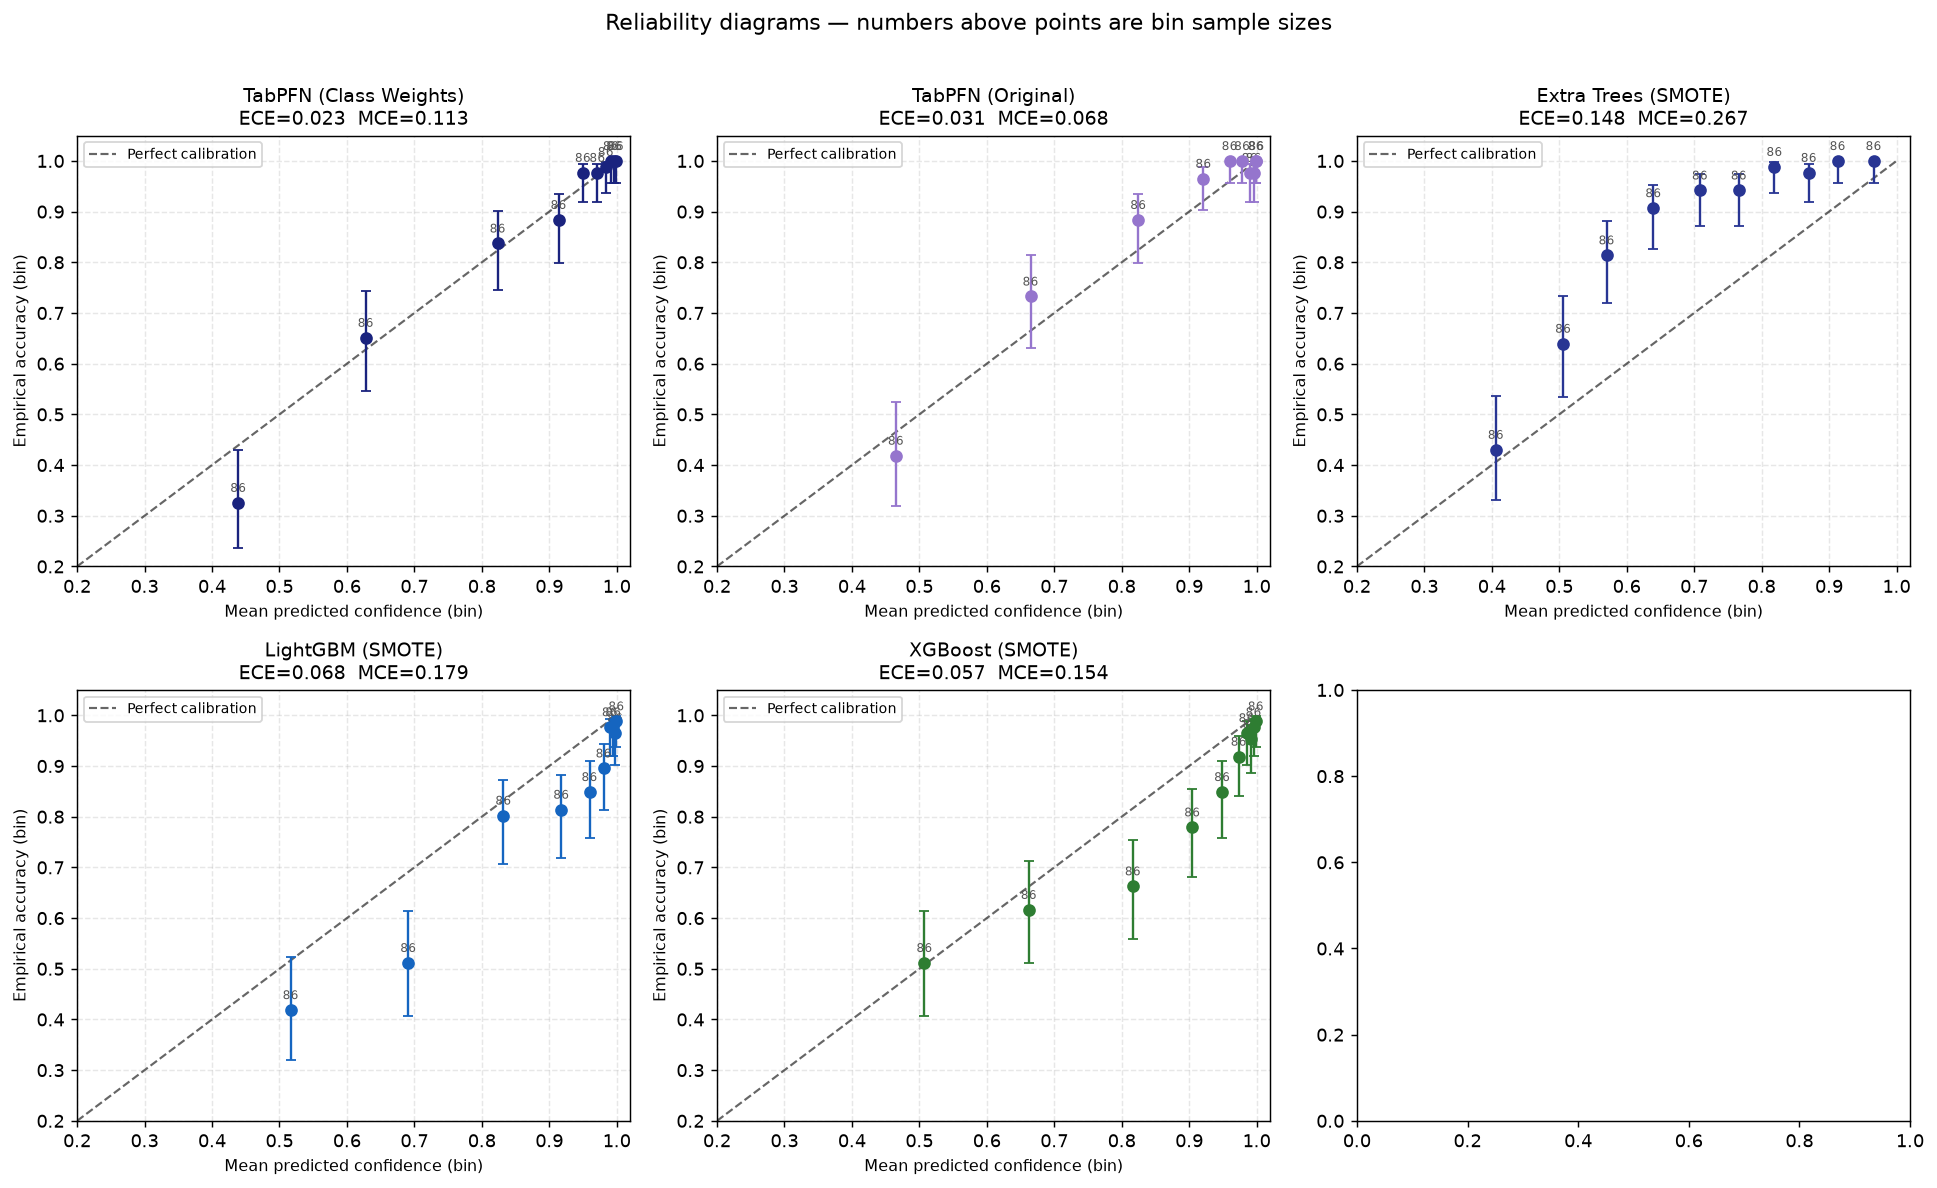

In [4]:
N_BINS = 10
all_bins = {}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flat

for ax, (key, label, _, _) in zip(axes, MODELS):
    d = pooled[key]
    bins = adaptive_bins(d['conf'], d['correct'], n_bins=N_BINS)
    all_bins[key] = bins

    ax.plot([0.2, 1.0], [0.2, 1.0], 'k--', linewidth=1.2, alpha=0.6, label='Perfect calibration')

    xs   = [b['mean_conf'] for b in bins]
    ys   = [b['accuracy']  for b in bins]
    los  = [b['accuracy'] - b['ci_lo'] for b in bins]
    his  = [b['ci_hi'] - b['accuracy'] for b in bins]
    ns   = [b['n'] for b in bins]

    ax.errorbar(xs, ys, yerr=[los, his], fmt='o', color=d['color'],
                ecolor=d['color'], elinewidth=1.3, capsize=3, markersize=6, zorder=3)

    for x, y, n in zip(xs, ys, ns):
        ax.annotate(str(n), (x, y), textcoords='offset points', xytext=(0, 6),
                    fontsize=6.5, ha='center', color='#555')

    ece = expected_calibration_error(bins, len(d['conf']))
    mce = max_calibration_error(bins)
    ax.set_title(f"{label}\nECE={ece:.3f}  MCE={mce:.3f}", fontsize=10.5)
    ax.set_xlim(0.2, 1.02)
    ax.set_ylim(0.2, 1.05)
    ax.set_xlabel('Mean predicted confidence (bin)', fontsize=9)
    ax.set_ylabel('Empirical accuracy (bin)', fontsize=9)
    ax.grid(linestyle='--', alpha=0.3)
    ax.legend(fontsize=7.5, loc='upper left')

for ax in list(axes):
    if not ax.has_data():
        ax.axis('off')

plt.suptitle('Reliability diagrams — numbers above points are bin sample sizes', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'calibration_reliability_diagrams.png'), dpi=200, bbox_inches='tight')
plt.show()

## 4  ECE / MCE / Brier summary table

In [5]:
rows = []
for key, label, fname, is_tabpfn in MODELS:
    d = pooled[key]
    bins = all_bins[key]
    ece = expected_calibration_error(bins, len(d['conf']))
    mce = max_calibration_error(bins)
    base_rate = d['correct'].mean()
    decomp = brier_decomposition(bins, len(d['conf']), base_rate)

    # Multiclass Brier needs the full probability vector, not just top-1 — reload once more, cheap
    probs_all, y_all = [], []
    for seed in SEEDS:
        path = os.path.join(seed_dir(seed, is_tabpfn), fname)
        df = pd.read_csv(path)
        pcols = PROB_COLS_NAMED if PROB_COLS_NAMED[0] in df.columns else PROB_COLS_INDEXED
        probs_all.append(df[pcols].values.astype(float))
        y_all.append(df['True_Label'].values.astype(int))
    probs_all = np.concatenate(probs_all)
    y_all = np.concatenate(y_all)
    mc_brier = multiclass_brier(probs_all, y_all)

    rows.append({
        'Model': label,
        'n': len(d['conf']),
        'Accuracy': round(base_rate, 3),
        'Mean confidence': round(d['conf'].mean(), 3),
        'ECE': round(ece, 4),
        'MCE': round(mce, 4),
        'Brier (multiclass)': round(mc_brier, 4),
        'Brier reliability (top-1)': round(decomp['reliability'], 5),
    })

summary_df = pd.DataFrame(rows).set_index('Model')
print('Lower ECE/MCE/Brier = better calibrated. "Mean confidence" vs "Accuracy" gap is the')
print('simplest overconfidence/underconfidence signal (positive gap = overconfident).\n')
summary_df

Lower ECE/MCE/Brier = better calibrated. "Mean confidence" vs "Accuracy" gap is the
simplest overconfidence/underconfidence signal (positive gap = overconfident).



,n,Accuracy,Mean confidence,ECE,MCE,Brier (multiclass),Brier reliability (top-1)
Model,,,,,,,
TabPFN (Class Weights),860,0.864,0.870,0.0231,0.1134,0.1818,0.00153
TabPFN (Original),860,0.895,0.880,0.0312,0.0676,0.1424,0.00148
Extra Trees (SMOTE),860,0.864,0.716,0.1475,0.2674,0.2393,0.02834
LightGBM (SMOTE),860,0.820,0.888,0.0682,0.1793,0.2628,0.00747
XGBoost (SMOTE),860,0.822,0.878,0.0571,0.1538,0.2779,0.00568


## 5  Per-bin significance test

For each bin, test H0: true accuracy equals the bin's mean stated confidence, using a
one-sample binomial test (correct count out of n, against the bin's mean confidence as
the null success probability). Holm-corrected across the 10 bins per model.

In [6]:
from statsmodels.stats.multitest import multipletests

for key, label, _, _ in MODELS:
    d = pooled[key]
    bins = all_bins[key]
    pvals = []
    for b in bins:
        k = int(round(b['accuracy'] * b['n']))
        res = stats.binomtest(k, b['n'], b['mean_conf'], alternative='two-sided')
        pvals.append(res.pvalue)
    reject, p_adj, _, _ = multipletests(pvals, method='holm')

    print(f"\n{label}:")
    any_sig = False
    for b, p_raw, p_a, rej in zip(bins, pvals, p_adj, reject):
        flag = '  <-- SIGNIFICANTLY MISCALIBRATED (p_holm={:.3f})'.format(p_a) if rej else ''
        if rej:
            any_sig = True
        print(f"  conf=[{b['min_conf']:.2f},{b['max_conf']:.2f}] (mean={b['mean_conf']:.3f}, n={b['n']:3d})"
              f"   acc={b['accuracy']:.3f} [{b['ci_lo']:.3f},{b['ci_hi']:.3f}]{flag}")
    if not any_sig:
        print('  No bin significantly miscalibrated after Holm correction (alpha=0.05).')


TabPFN (Class Weights):
  conf=[0.29,0.53] (mean=0.439, n= 86)   acc=0.326 [0.236,0.430]
  conf=[0.53,0.74] (mean=0.628, n= 86)   acc=0.651 [0.546,0.743]
  conf=[0.74,0.89] (mean=0.824, n= 86)   acc=0.837 [0.745,0.900]
  conf=[0.89,0.94] (mean=0.914, n= 86)   acc=0.884 [0.799,0.936]
  conf=[0.94,0.96] (mean=0.950, n= 86)   acc=0.977 [0.919,0.994]
  conf=[0.96,0.98] (mean=0.971, n= 86)   acc=0.977 [0.919,0.994]
  conf=[0.98,0.99] (mean=0.984, n= 86)   acc=0.988 [0.937,0.998]
  conf=[0.99,0.99] (mean=0.991, n= 86)   acc=1.000 [0.957,1.000]
  conf=[0.99,1.00] (mean=0.996, n= 86)   acc=1.000 [0.957,1.000]
  conf=[1.00,1.00] (mean=0.999, n= 86)   acc=1.000 [0.957,1.000]
  No bin significantly miscalibrated after Holm correction (alpha=0.05).



TabPFN (Original):
  conf=[0.33,0.55] (mean=0.465, n= 86)   acc=0.419 [0.320,0.524]
  conf=[0.55,0.75] (mean=0.665, n= 86)   acc=0.733 [0.631,0.815]
  conf=[0.75,0.89] (mean=0.825, n= 86)   acc=0.884 [0.799,0.936]
  conf=[0.89,0.94] (mean=0.921, n= 86)   acc=0.965 [0.902,0.988]
  conf=[0.94,0.97] (mean=0.960, n= 86)   acc=1.000 [0.957,1.000]
  conf=[0.97,0.99] (mean=0.979, n= 86)   acc=1.000 [0.957,1.000]
  conf=[0.99,0.99] (mean=0.990, n= 86)   acc=0.977 [0.919,0.994]
  conf=[0.99,1.00] (mean=0.996, n= 86)   acc=0.977 [0.919,0.994]
  conf=[1.00,1.00] (mean=0.999, n= 86)   acc=1.000 [0.957,1.000]
  conf=[1.00,1.00] (mean=1.000, n= 86)   acc=1.000 [0.957,1.000]
  No bin significantly miscalibrated after Holm correction (alpha=0.05).

Extra Trees (SMOTE):
  conf=[0.26,0.46] (mean=0.406, n= 86)   acc=0.430 [0.331,0.536]
  conf=[0.46,0.54] (mean=0.506, n= 86)   acc=0.640 [0.534,0.733]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.040)
  conf=[0.54,0.60] (mean=0.570, n= 86)   acc=0.814 [0.719


LightGBM (SMOTE):
  conf=[0.35,0.61] (mean=0.517, n= 86)   acc=0.419 [0.320,0.524]
  conf=[0.61,0.77] (mean=0.691, n= 86)   acc=0.512 [0.408,0.614]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.005)
  conf=[0.77,0.88] (mean=0.832, n= 86)   acc=0.802 [0.706,0.873]
  conf=[0.89,0.94] (mean=0.918, n= 86)   acc=0.814 [0.719,0.882]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.013)
  conf=[0.94,0.97] (mean=0.960, n= 86)   acc=0.849 [0.758,0.909]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.000)
  conf=[0.97,0.99] (mean=0.981, n= 86)   acc=0.895 [0.813,0.944]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.000)
  conf=[0.99,0.99] (mean=0.990, n= 86)   acc=0.977 [0.919,0.994]
  conf=[0.99,1.00] (mean=0.995, n= 86)   acc=0.977 [0.919,0.994]
  conf=[1.00,1.00] (mean=0.998, n= 86)   acc=0.965 [0.902,0.988]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.007)
  conf=[1.00,1.00] (mean=1.000, n= 86)   acc=0.988 [0.937,0.998]



XGBoost (SMOTE):
  conf=[0.32,0.59] (mean=0.508, n= 86)   acc=0.512 [0.408,0.614]
  conf=[0.59,0.76] (mean=0.662, n= 86)   acc=0.616 [0.511,0.712]
  conf=[0.76,0.87] (mean=0.817, n= 86)   acc=0.663 [0.558,0.754]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.005)
  conf=[0.87,0.93] (mean=0.905, n= 86)   acc=0.779 [0.681,0.854]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.005)
  conf=[0.93,0.96] (mean=0.949, n= 86)   acc=0.849 [0.758,0.909]  <-- SIGNIFICANTLY MISCALIBRATED (p_holm=0.004)
  conf=[0.96,0.98] (mean=0.973, n= 86)   acc=0.919 [0.841,0.960]
  conf=[0.98,0.99] (mean=0.985, n= 86)   acc=0.965 [0.902,0.988]
  conf=[0.99,0.99] (mean=0.991, n= 86)   acc=0.953 [0.886,0.982]
  conf=[0.99,1.00] (mean=0.995, n= 86)   acc=0.977 [0.919,0.994]
  conf=[1.00,1.00] (mean=0.999, n= 86)   acc=0.988 [0.937,0.998]


## 6  Per-seed ECE stability

Is the pooled ECE representative, or does calibration quality itself swing wildly from
seed to seed? Each seed only has 86 points, so per-seed bins are coarse (5 bins) — this
is a stability check, not a precise per-seed estimate.

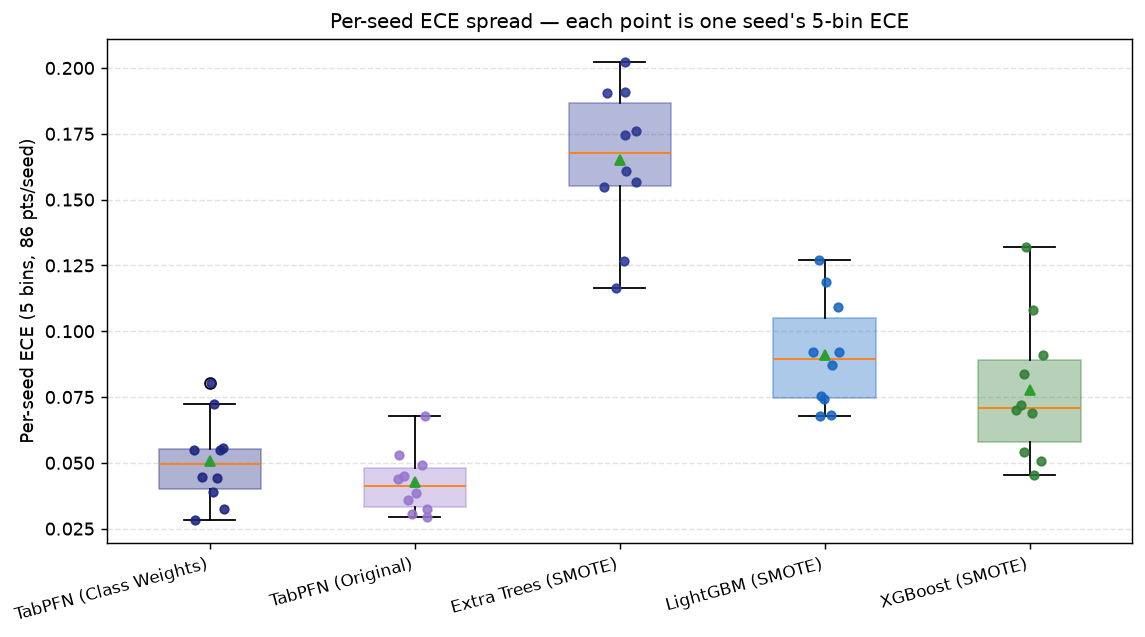

,TabPFN (Class Weights),TabPFN (Original),Extra Trees (SMOTE),LightGBM (SMOTE),XGBoost (SMOTE)
42,0.072,0.068,0.155,0.068,0.069
123,0.045,0.044,0.190,0.075,0.054
456,0.028,0.032,0.174,0.092,0.108
789,0.055,0.053,0.191,0.087,0.084
1011,0.055,0.049,0.127,0.119,0.132
1213,0.056,0.045,0.116,0.127,0.091
1415,0.039,0.029,0.157,0.074,0.072
1617,0.044,0.039,0.176,0.109,0.045
1819,0.080,0.036,0.161,0.092,0.070
2021,0.032,0.031,0.202,0.068,0.051


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

per_seed_ece = {key: [] for key, _, _, _ in MODELS}
for key, label, _, _ in MODELS:
    d = pooled[key]
    for seed in SEEDS:
        mask = d['seed'] == seed
        bins_s = adaptive_bins(d['conf'][mask], d['correct'][mask], n_bins=5)
        per_seed_ece[key].append(expected_calibration_error(bins_s, mask.sum()))

positions = range(len(MODELS))
labels = [label for _, label, _, _ in MODELS]
colors = [_display_color[key] for key, _, _, _ in MODELS]

bp = ax.boxplot([per_seed_ece[key] for key, _, _, _ in MODELS], positions=positions,
                widths=0.5, patch_artist=True, showmeans=True)
for patch, col in zip(bp['boxes'], colors):
    patch.set_facecolor(col)
    patch.set_alpha(0.35)
    patch.set_edgecolor(col)

rng = np.random.default_rng(0)
for i, key in enumerate([k for k, _, _, _ in MODELS]):
    vals = per_seed_ece[key]
    jitter = rng.uniform(-0.08, 0.08, size=len(vals))
    ax.scatter(np.full(len(vals), i) + jitter, vals, color=colors[i], s=22, zorder=4, alpha=0.85)

ax.set_xticks(list(positions))
ax.set_xticklabels(labels, fontsize=9.5, rotation=15, ha='right')
ax.set_ylabel('Per-seed ECE (5 bins, 86 pts/seed)', fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.set_axisbelow(True)
ax.set_title('Per-seed ECE spread — each point is one seed\'s 5-bin ECE', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'calibration_per_seed_ece.png'), dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame({label: per_seed_ece[key] for key, label, _, _ in MODELS}, index=SEEDS).round(3)

## 7  Confidence distribution — are these models overconfident by construction?

If confidences cluster near 1.0 regardless of correctness, that alone signals
overconfidence before even computing ECE.

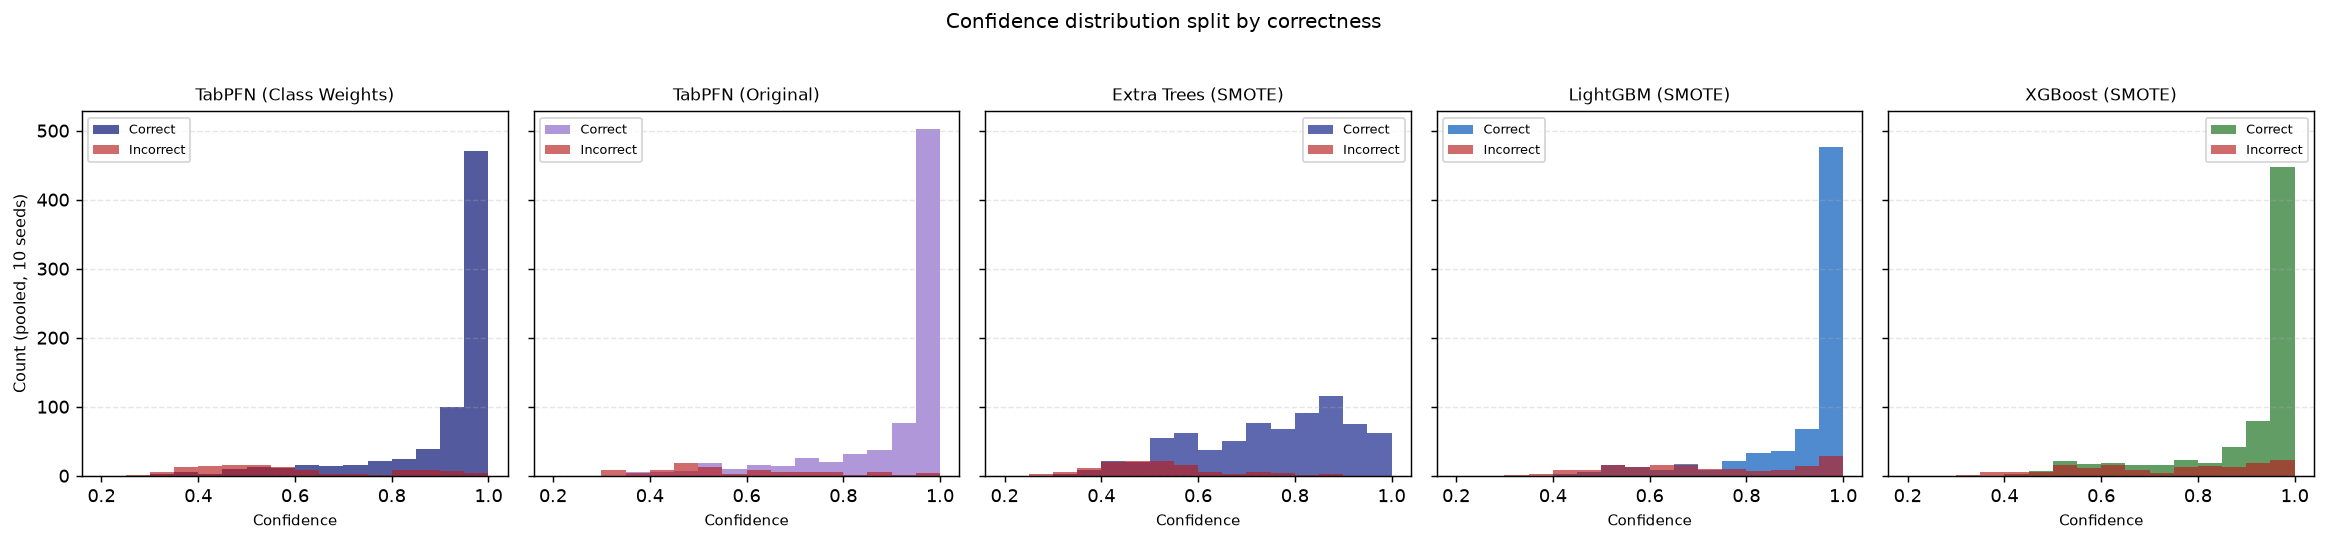

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True)

for ax, (key, label, _, _) in zip(axes, MODELS):
    d = pooled[key]
    correct_conf   = d['conf'][d['correct'] == 1]
    incorrect_conf = d['conf'][d['correct'] == 0]
    bins_edges = np.linspace(0.2, 1.0, 17)
    ax.hist(correct_conf, bins=bins_edges, color=d['color'], alpha=0.75, label='Correct')
    ax.hist(incorrect_conf, bins=bins_edges, color='#b71c1c', alpha=0.65, label='Incorrect')
    ax.set_title(label, fontsize=9.5)
    ax.set_xlabel('Confidence', fontsize=8.5)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.legend(fontsize=7)

axes[0].set_ylabel('Count (pooled, 10 seeds)', fontsize=9)
plt.suptitle('Confidence distribution split by correctness', fontsize=11, y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'calibration_confidence_distribution.png'), dpi=200, bbox_inches='tight')
plt.show()

## 8  Does `balance_probabilities` hurt calibration? (TabPFN Original vs. Class Weights)

`balance_probabilities=True` rescales TabPFN's posterior by class frequency specifically
to improve balanced accuracy on imbalanced data (see paper §Effects of class imbalance
handling strategies). That rescaling has no obligation to preserve calibration — this is
a direct empirical check of whether the accuracy gain comes at a calibration cost.

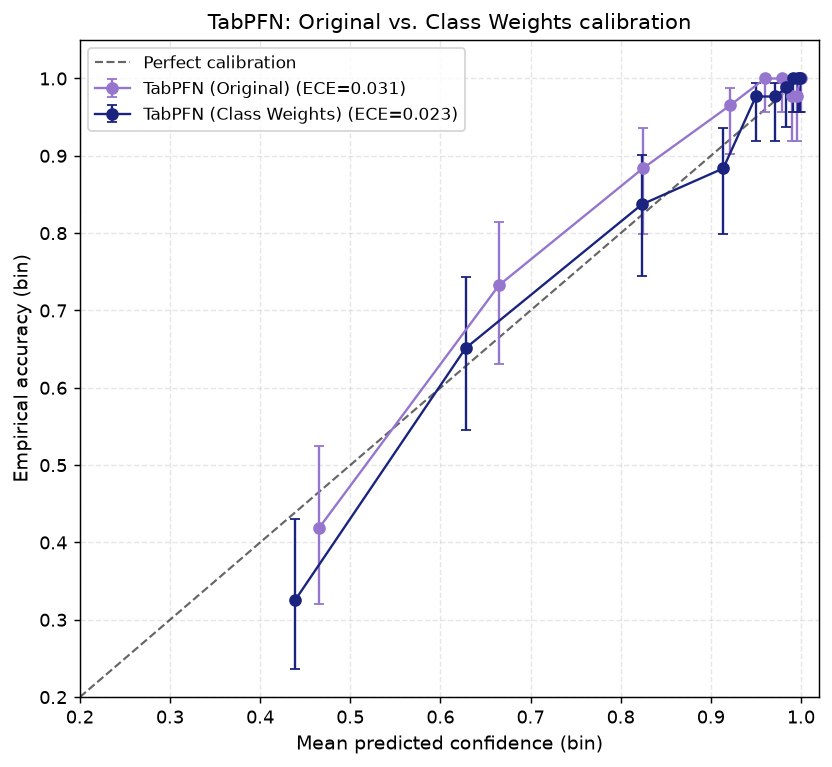

ECE — Original: 0.0312   Class Weights: 0.0231   Delta: -0.0081 (better calibration with rebalancing)


In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6))

ax.plot([0.2, 1.0], [0.2, 1.0], 'k--', linewidth=1.2, alpha=0.6, label='Perfect calibration')

for key in ['tabpfn_original', 'tabpfn_cw']:
    d = pooled[key]
    bins = all_bins[key]
    xs = [b['mean_conf'] for b in bins]
    ys = [b['accuracy'] for b in bins]
    los = [b['accuracy'] - b['ci_lo'] for b in bins]
    his = [b['ci_hi'] - b['accuracy'] for b in bins]
    ece = expected_calibration_error(bins, len(d['conf']))
    ax.errorbar(xs, ys, yerr=[los, his], fmt='o-', color=d['color'], capsize=3,
                markersize=6, linewidth=1.3, label=f"{d['label']} (ECE={ece:.3f})")

ax.set_xlim(0.2, 1.02)
ax.set_ylim(0.2, 1.05)
ax.set_xlabel('Mean predicted confidence (bin)', fontsize=10.5)
ax.set_ylabel('Empirical accuracy (bin)', fontsize=10.5)
ax.legend(fontsize=9.5, loc='upper left')
ax.grid(linestyle='--', alpha=0.3)
ax.set_title('TabPFN: Original vs. Class Weights calibration', fontsize=11.5)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'calibration_tabpfn_rebalancing_effect.png'), dpi=200, bbox_inches='tight')
plt.show()

ece_o = expected_calibration_error(all_bins['tabpfn_original'], len(pooled['tabpfn_original']['conf']))
ece_c = expected_calibration_error(all_bins['tabpfn_cw'], len(pooled['tabpfn_cw']['conf']))
print(f"ECE — Original: {ece_o:.4f}   Class Weights: {ece_c:.4f}   "
      f"Delta: {ece_c - ece_o:+.4f} ({'worse' if ece_c > ece_o else 'better'} calibration with rebalancing)")

## 9  Per-class calibration

Does a 0.89 prediction mean the same thing when the predicted class is Allele vs.
Forward Stutter? Reports ECE computed separately within each *predicted* class (fewer
bins, since per-class n is small — Forward Stutter in particular will be sparse).

In [10]:
N_BINS_PERCLASS = 4
rows = []
for key, label, _, _ in MODELS:
    d = pooled[key]
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        mask = d['y_pred'] == cls_idx
        n = mask.sum()
        if n < N_BINS_PERCLASS * 3:
            rows.append({'Model': label, 'Predicted class': cls_name, 'n': n,
                         'Accuracy': np.nan, 'Mean conf.': np.nan, 'ECE': np.nan,
                         'Note': 'too few predictions to bin'})
            continue
        bins = adaptive_bins(d['conf'][mask], d['correct'][mask], n_bins=N_BINS_PERCLASS)
        ece = expected_calibration_error(bins, n)
        rows.append({
            'Model': label, 'Predicted class': cls_name, 'n': n,
            'Accuracy': round(d['correct'][mask].mean(), 3),
            'Mean conf.': round(d['conf'][mask].mean(), 3),
            'ECE': round(ece, 4), 'Note': '',
        })

perclass_df = pd.DataFrame(rows)
perclass_df.set_index(['Model', 'Predicted class'])

n  Accuracy  Mean conf.     ECE Note
Model                  Predicted class                                        
TabPFN (Class Weights) Allele           384     0.979       0.923  0.0626     
                       Back Stutter     186     0.849       0.857  0.0465     
                       Forward Stutter  112     0.527       0.726  0.1994     
                       Pull-Up          178     0.843       0.857  0.0387     
TabPFN (Original)      Allele           452     0.927       0.904  0.0271     
                       Back Stutter     175     0.903       0.877  0.0255     
                       Forward Stutter   62     0.694       0.717  0.0894     
                       Pull-Up          171     0.877       0.876  0.0367     
Extra Trees (SMOTE)    Allele           434     0.912       0.750  0.1623     
                       Back Stutter     189     0.825       0.709  0.1602     
                       Forward Stutter   72     0.639       0.569  0.1044     
                       Pull-Up          165     0.879       0.700  0.1788     
LightGBM (SMOTE)       Allele           404     0.911       0.909  0.0080     
                       Back Stutter     194     0.753       0.886  0.1336     
                       Forward Stutter   81     0.605       0.847  0.2426     
                       Pull-Up          181     0.785       0.861  0.0767     
XGBoost (SMOTE)        Allele           423     0.896       0.890  0.0149     
                       Back Stutter     189     0.757       0.894  0.1379     
                       Forward Stutter   78     0.603       0.855  0.2522     
                       Pull-Up          170     0.812       0.843  0.0357

## 10  Summary

In [11]:
print('=' * 72)
print('CALIBRATION SUMMARY (pooled across 10 seeds, n per model shown above)')
print('=' * 72)
for key, label, _, _ in MODELS:
    d = pooled[key]
    bins = all_bins[key]
    ece = expected_calibration_error(bins, len(d['conf']))
    gap = d['conf'].mean() - d['correct'].mean()
    direction = 'overconfident' if gap > 0.01 else ('underconfident' if gap < -0.01 else 'well-calibrated on average')
    print(f"{label:28s}  ECE={ece:.4f}  mean conf - accuracy = {gap:+.4f}  ({direction})")
print()
print('A model is well-calibrated if ECE is small (no fixed threshold, but <0.02-0.03 is')
print('typically considered good for a 4-class problem) and no reliability-diagram bin is')
print('flagged as significantly miscalibrated in Section 5. Section 6 shows whether this')
print('holds up seed-by-seed or is an artefact of pooling; Section 8 answers specifically')
print('whether balance_probabilities trades calibration for balanced accuracy.')

CALIBRATION SUMMARY (pooled across 10 seeds, n per model shown above)
TabPFN (Class Weights)        ECE=0.0231  mean conf - accuracy = +0.0056  (well-calibrated on average)
TabPFN (Original)             ECE=0.0312  mean conf - accuracy = -0.0155  (underconfident)
Extra Trees (SMOTE)           ECE=0.1475  mean conf - accuracy = -0.1475  (underconfident)
LightGBM (SMOTE)              ECE=0.0682  mean conf - accuracy = +0.0682  (overconfident)
XGBoost (SMOTE)               ECE=0.0571  mean conf - accuracy = +0.0563  (overconfident)

A model is well-calibrated if ECE is small (no fixed threshold, but <0.02-0.03 is
typically considered good for a 4-class problem) and no reliability-diagram bin is
flagged as significantly miscalibrated in Section 5. Section 6 shows whether this
holds up seed-by-seed or is an artefact of pooling; Section 8 answers specifically
whether balance_probabilities trades calibration for balanced accuracy.
